In [ ]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

import hashlib
import math
import random
import re
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "openai-community/gpt2"
MAX_LEN = 768
MAX_NEW = 400
N_EVAL = 40
EPOCHS = 2
BATCH = 8
TRAIN_LIMIT = None
OUT = Path("/kaggle/working/recipe_lab") if Path("/kaggle/working").is_dir() else Path("recipe_lab_outputs")
DATA_DIR, ADAPTER_DIR = OUT / "data", OUT / "adapter"
HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-3 only)")

torch 2.11.0+cu130 | transformers 5.21.0
GPU: Tesla T4


In [ ]:
DATA_URL = ("https://data.mendeley.com/public-files/datasets/xsphgmmh7b/files/"
            "6fb5ae32-a815-4b8f-9d68-8d512227eac8/file_downloaded")
DATA_SHA256 = "273f8d45f41aca9af0396dda07af137c68c7387a1506992904144b944c4346be"
csv_path = DATA_DIR / "IndianFoodDatasetCSV.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not csv_path.exists():
    print("downloading to", csv_path)
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "recipe-lab"})
    with urllib.request.urlopen(request) as response:
        csv_path.write_bytes(response.read())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == DATA_SHA256, "unexpected file: delete it and download again"

raw = pd.read_csv(csv_path, encoding="utf-8-sig")
raw = raw.apply(lambda col: col if pd.api.types.is_numeric_dtype(col) else col.str.replace("\ufeff", "").str.strip())
print(raw.shape)
print(raw.columns.tolist())
raw.iloc[0][["RecipeName", "Cuisine", "Course", "Diet", "Ingredients", "Instructions"]].to_dict()

(6871, 15)
['Srno', 'RecipeName', 'TranslatedRecipeName', 'Ingredients', 'TranslatedIngredients', 'PrepTimeInMins', 'CookTimeInMins', 'TotalTimeInMins', 'Servings', 'Cuisine', 'Course', 'Diet', 'Instructions', 'TranslatedInstructions', 'URL']


{'RecipeName': 'Masala Karela Recipe',
 'Cuisine': 'Indian',
 'Course': 'Side Dish',
 'Diet': 'Diabetic Friendly',
 'Ingredients': '6 Karela (Bitter Gourd/ Pavakkai) - deseeded,Salt - to taste,1 Onion - thinly sliced,3 tablespoon Gram flour (besan),2 teaspoons Turmeric powder (Haldi),1 tablespoon Red Chilli powder,2 teaspoons Cumin seeds (Jeera),1 tablespoon Coriander Powder (Dhania),1 tablespoon Amchur (Dry Mango Powder),Sunflower Oil - as required',
 'Instructions': 'To begin making the\xa0Masala Karela Recipe,de-seed the karela and slice. Do not remove the skin as the skin has all the nutrients.\xa0Add the karela to the pressure cooker with 3 tablespoon of water, salt and turmeric powder and pressure cook for three whistles. Release the pressure immediately and open the lids. Keep aside.Heat oil in a heavy bottomed pan or a kadhai. Add cumin seeds and let it sizzle.Once the cumin seeds have sizzled, add onions and saute them till it turns golden brown in color.Add the karela,\xa0red

In [ ]:
DEVANAGARI = r"[\u0900-\u097F]"
NOT_INDIAN = {"Afghan", "African", "American", "Arab", "Asian", "British", "Burmese", "Cantonese", "Caribbean",
              "Chinese", "Continental", "European", "French", "Fusion", "Greek", "Hunan", "Indonesian",
              "Italian Recipes", "Japanese", "Jewish", "Korean", "Malaysian", "Mediterranean", "Mexican",
              "Middle Eastern", "Nepalese", "Pakistani", "Shandong", "Sichuan", "Sri Lankan", "Thai",
              "Vietnamese", "World Breakfast",
              "Appetizer", "Brunch", "Dessert", "Dinner", "Lunch", "Side Dish", "Snack"}


def clean_text(t):
    t = re.sub(r"\.(?=[A-Z])", ". ", t)
    t = re.sub(r",(?=[A-Za-z])", ", ", t)
    return " ".join(t.split())


def clean_name(name):
    return " ".join(re.sub(r"\brecipe\b", "", name, flags=re.IGNORECASE).split()).strip(" -")


english = ~(raw["RecipeName"].str.contains(DEVANAGARI) | raw["Ingredients"].fillna("").str.contains(DEVANAGARI)
            | raw["Instructions"].str.contains(DEVANAGARI))
kept = raw[english & raw["Ingredients"].notna() & ~raw["Cuisine"].isin(NOT_INDIAN)]
recipes = [{"raw_name": r.RecipeName, "name": clean_name(r.RecipeName), "cuisine": r.Cuisine,
            "course": r.Course, "diet": r.Diet,
            "ingredients": [i.strip() for i in r.Ingredients.split(",") if i.strip()],
            "method": clean_text(r.Instructions)} for r in kept.itertuples()]
print(f"{len(raw):,} rows -> {english.sum():,} English originals -> {len(recipes):,} Indian recipes")
print(kept["Cuisine"].value_counts().head(8).to_string())

6,871 rows -> 5,659 English originals -> 3,708 Indian recipes
Cuisine
Indian                   870
North Indian Recipes     688
South Indian Recipes     503
Maharashtrian Recipes    144
Bengali Recipes          140
Karnataka                132
Kerala Recipes           126
Tamil Nadu               124


In [ ]:
def dish_key(raw_name):
    name = raw_name.lower().split(" - ", 1)[0].split("(", 1)[0]
    name = re.sub(r"\brecipes?\b", " ", name)
    name = re.sub(r"[^a-z ]", " ", name)
    return " ".join(name.split())


In [ ]:
assert dish_key("Aamras Recipe - Ripe Mango Ras") == dish_key("Aamras Recipe") == "aamras"
assert dish_key("Achari Paneer Masala Recipe") == "achari paneer masala"
assert dish_key("Bengali Doi Maach Recipe (Fish In Yogurt Curry)") == "bengali doi maach"
for r in recipes:
    r["key"] = dish_key(r["raw_name"])


keys = sorted({r["key"] for r in recipes})
random.Random(SEED).shuffle(keys)
n_val = n_test = len(keys) // 10
split_of = {k: "val" for k in keys[:n_val]} | {k: "test" for k in keys[n_val:n_val + n_test]} \
         | {k: "train" for k in keys[n_val + n_test:]}
splits = {s: [r for r in recipes if split_of[r["key"]] == s] for s in ("train", "val", "test")}
assert not ({r["key"] for r in splits["train"]} & {r["key"] for r in splits["val"] + splits["test"]})
print({s: len(rs) for s, rs in splits.items()}, f"| {len(keys):,} distinct dishes")


shuffled = random.Random(SEED).sample(recipes, len(recipes))
row_val, row_train = shuffled[:len(recipes) // 10], shuffled[len(recipes) // 10:]
train_keys = {r["key"] for r in row_train}
twins = [r for r in row_val if r["key"] in train_keys]
print(f"random row split: {len(twins)} of {len(row_val)} validation recipes have a same-dish twin in training")
for r in twins[:3]:
    print("  ", r["raw_name"], "<->", next(t["raw_name"] for t in row_train if t["key"] == r["key"]))
print("Exercise 1 checks passed.")

{'train': 2970, 'val': 369, 'test': 369} | 3,694 distinct dishes
random row split: 6 of 370 validation recipes have a same-dish twin in training
   Badam Halwa Recipe - Delicious Almond Halwa With Khoya <-> Badam Halwa Recipe
   Jal Jeera Recipe - Sweet And Sour Cumin Water Recipe <-> Jal Jeera Recipe - Indian Spiced Lemonade
   Muttaikose Poriyal Recipe -  Purple Cabbage Poriyal | Red Cabbage Sabzi <-> Muttaikose Poriyal Recipe - Cabbage Stir fry With Coconut
Exercise 1 checks passed.


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CKPT)
tokenizer.pad_token = tokenizer.eos_token


def format_prompt(r):
    ingredients = "\n".join(f"- {i}" for i in r["ingredients"])
    return (f"Dish: {r['name']}\nCuisine: {r['cuisine']} | Course: {r['course']} | Diet: {r['diet']}\n"
            f"Ingredients:\n{ingredients}\nMethod:\n")


def prompt_ids(r, tok, add_bos):
    """Token IDs of the prompt. GPT-2 uses no beginning-of-text token; Llama does (see the extension)."""
    ids = tok(format_prompt(r), add_special_tokens=False)["input_ids"]
    return ([tok.bos_token_id] if add_bos else []) + ids


r0 = splits["train"][0]
print(format_prompt(r0) + r0["method"][:300] + " …")
print("\nend-of-text token:", repr(tokenizer.eos_token), tokenizer.eos_token_id)
for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
    print(f"{word:>8} -> {tokenizer.tokenize(' ' + word)}")

Dish: Ragi Semiya Upma - Ragi Millet Vermicelli Breakfast
Cuisine: South Indian Recipes | Course: South Indian Breakfast | Diet: High Protein Vegetarian
Ingredients:
- 1-1/2 cups Rice Vermicelli Noodles (Thin)
- 1 Onion - sliced
- 1/2 cup Carrots (Gajjar) - chopped
- 1/3 cup Green peas (Matar)
- 2 Green Chillies
- 1/4 teaspoon Asafoetida (hing)
- 1 teaspoon Mustard seeds
- 1 teaspoon White Urad Dal (Split)
- 1 teaspoon Ghee
- 1 sprig Curry leaves
- Salt - to taste
- 1 teaspoon Lemon juice
Method:
To begin making the Ragi Vermicelli Recipe, first steam the ragi vermicelli in a rice cooker or a steamer for about 5-6 minutes or till it is cooked but firm. Keep aside this aside till later use. You can add a few drops of oil and mix it so that they don't stick to each other. Place a kadai on the  …

end-of-text token: '<|endoftext|>' 50256
  potato -> ['Ġpotato']
   cumin -> ['Ġc', 'umin']
  karela -> ['Ġk', 'are', 'la']
  amchur -> ['Ġam', 'ch', 'ur']
  kadhai -> ['Ġk', 'adh', 'ai']
   tad

In [ ]:
def build_example(r, tok, add_bos):
    prompt = prompt_ids(r, tok, add_bos)
    answer = tok(r["method"], add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    input_ids = prompt + answer
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids),
            "labels": [-100] * len(prompt) + answer}


In [ ]:
ex = build_example(r0, tokenizer, add_bos=False)
n_prompt = len(prompt_ids(r0, tokenizer, add_bos=False))
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "method labels must equal the method tokens"
assert ex["input_ids"][-1] == tokenizer.eos_token_id, "the method must end with the end-of-text token"
assert tokenizer.decode(ex["input_ids"][:n_prompt], clean_up_tokenization_spaces=False) == format_prompt(r0)
print(f"{len(ex['input_ids'])} tokens, {len(ex['input_ids']) - n_prompt} of them scored")
print("scored text ends with:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])[-80:]))


def make_dataset(rows, tok, add_bos):
    data = [build_example(r, tok, add_bos) for r in rows]
    return [e for e in data if len(e["input_ids"]) <= MAX_LEN]


train_rows = splits["train"][:TRAIN_LIMIT]
train_data = make_dataset(train_rows, tokenizer, add_bos=False)
val_data = make_dataset(splits["val"], tokenizer, add_bos=False)
eval_rows = random.Random(SEED).sample(splits["val"], N_EVAL)
lengths = sorted(len(build_example(r, tokenizer, False)["input_ids"]) for r in train_rows)
print(f"training examples: {len(train_data):,} kept of {len(train_rows):,} (> {MAX_LEN} tokens dropped)"
      f" | validation examples: {len(val_data)}")
print(f"tokens per example: median {lengths[len(lengths) // 2]}, 90th percentile {lengths[int(0.9 * len(lengths))]}, "
      f"max {lengths[-1]}")
print("Exercise 2 checks passed.")

423 tokens, 261 of them scored
scored text ends with: 't Chutney and a hot cup of coffee or tea for a wholesome breakfast.<|endoftext|>'
training examples: 2,862 kept of 2,970 (> 768 tokens dropped) | validation examples: 359
tokens per example: median 430, 90th percentile 636, max 1337
Exercise 2 checks passed.


In [ ]:
!pip install -q sacrebleu rouge-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import sacrebleu
from rouge_score import rouge_scorer

ROUGE_KEYS = {"ROUGE-1": "rouge1", "ROUGE-2": "rouge2", "ROUGE-L": "rougeL"}
scorer = rouge_scorer.RougeScorer(list(ROUGE_KEYS.values()), use_stemmer=True)

def text_metrics(preds, refs):
    bleu = sacrebleu.corpus_bleu(preds, [refs]).score
    totals = {name: 0.0 for name in ROUGE_KEYS}
    for pred, ref in zip(preds, refs):
        scores = scorer.score(ref, pred)
        for name, key in ROUGE_KEYS.items():
            totals[name] += scores[key].fmeasure
    n = max(len(preds), 1)
    return {"BLEU": bleu, **{name: 100 * value / n for name, value in totals.items()}}


In [ ]:
m = text_metrics(["heat oil in a pan"], ["heat the oil in a kadhai"])
print({k: round(v, 1) for k, v in m.items()})
assert abs(m["ROUGE-1"] - 72.7) < 0.1 and abs(m["ROUGE-2"] - 44.4) < 0.1 and abs(m["ROUGE-L"] - 72.7) < 0.1
assert abs(text_metrics(["add salt and stir well"], ["add salt and stir well"])["BLEU"] - 100) < 1e-6
print("Exercise 3 checks passed.")

{'BLEU': 35.0, 'ROUGE-1': 72.7, 'ROUGE-2': 44.4, 'ROUGE-L': 72.7}
Exercise 3 checks passed.


In [ ]:
UNITS = r"\b(cups?|tablespoons?|teaspoons?|tbsp|tsp|grams?|gms?|g|kg|ml|litres?|liters?|inch|pinch|sprigs?|cloves?|pieces?|nos?)\b"


def ingredient_words(ingredients):
    words = set()
    for item in ingredients:
        name = re.split(r" - |\(", item.lower())[0]
        name = re.sub(UNITS, " ", re.sub(r"[^a-z ]", " ", name))
        if name.split():
            words.add(name.split()[-1])
    return words


def ingredient_coverage(rows, methods):
    fractions = []
    for r, m in zip(rows, methods):
        words, text = ingredient_words(r["ingredients"]), set(re.findall(r"[a-z]+", m.lower()))
        fractions.append(len(words & text) / max(len(words), 1))
    return 100 * sum(fractions) / len(fractions)


print(sorted(ingredient_words(r0["ingredients"])))
print(f"reference methods mention {ingredient_coverage(eval_rows, [r['method'] for r in eval_rows]):.0f}% "
      "of their ingredient words (validation sample)")

['asafoetida', 'carrots', 'chillies', 'dal', 'ghee', 'juice', 'leaves', 'noodles', 'onion', 'peas', 'salt', 'seeds']
reference methods mention 77% of their ingredient words (validation sample)


In [ ]:
from transformers import AutoModelForCausalLM


@torch.no_grad()
def generate_methods(model, tok, rows, add_bos, batch_size=8, max_new_tokens=MAX_NEW):
    model.eval()
    texts, stopped = [], []
    for i in range(0, len(rows), batch_size):
        prompts = [prompt_ids(r, tok, add_bos) for r in rows[i:i + batch_size]]
        width = max(len(p) for p in prompts)
        ids = torch.full((len(prompts), width), tok.pad_token_id)
        mask = torch.zeros((len(prompts), width), dtype=torch.long)
        for j, p in enumerate(prompts):
            ids[j, width - len(p):] = torch.tensor(p)
            mask[j, width - len(p):] = 1
        out = model.generate(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), do_sample=False,
                             temperature=None, top_p=None, top_k=None, no_repeat_ngram_size=4,
                             max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id,
                             eos_token_id=tok.eos_token_id)
        for new in out[:, width:].tolist():
            stop = tok.eos_token_id in new
            new = new[:new.index(tok.eos_token_id)] if stop else new
            texts.append(tok.decode(new, skip_special_tokens=True).strip())
            stopped.append(stop)
    return texts, stopped


refs = [r["method"] for r in eval_rows]
results = {}


def evaluate(name, preds, stopped, rows=None):
    rows = eval_rows if rows is None else rows
    row = text_metrics(preds, [r["method"] for r in rows])
    row["ingredients %"] = ingredient_coverage(rows, preds)
    row["words"] = sum(len(p.split()) for p in preds) / len(preds)
    row["stopped %"] = 100 * sum(stopped) / len(stopped)
    results[name] = row
    return pd.DataFrame(results).T.round(1)


transformers.set_seed(SEED)
base_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
start = time.perf_counter()
base_preds, base_stopped = generate_methods(base_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {len(base_preds)} methods in {time.perf_counter() - start:.0f} s")
reference_row = {"ingredients %": ingredient_coverage(eval_rows, refs), "words": sum(len(t.split()) for t in refs) / len(refs)}
print("references:", {k: round(v, 1) for k, v in reference_row.items()})
evaluate("GPT-2 original", base_preds, base_stopped)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

generated 40 methods in 43 s
references: {'ingredients %': 76.9, 'words': 234.2}


,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,ingredients %,words,stopped %
GPT-2 original,3.7,30.8,6.9,17.4,56.3,219.0,65.0


In [ ]:
for r, p in list(zip(eval_rows, base_preds))[:2]:
    print(f"=== {r['name']} ===\nMODEL:     {p[:600]}\nREFERENCE: {r['method'][:600]}\n")

=== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===
MODEL:     - In a large bowl, combine the milk, water, ginger, cardamom powder, cardamoms, and ghee. Add the milk and mix well. Add the yogurt and mix well again. Add the dry ginger powder and mix well, adding more milk if needed. Add the ginger and mix well and add more milk if necessary. Add the water and mix well to combine. Add the ghee and mix well until the mixture is smooth. Add the remaining milk and mix. Add the rest of the ingredients and mix well with a fork. Serve hot.
- Serve hot. Recipe Notes:
- The recipe is based on a recipe from the Indian Food Journal.
- The Indian Food Journal is a web
REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken.

In [ ]:
from transformers import Trainer, TrainingArguments

FULL_LR = 5e-5

def make_args(name, lr):
    return TrainingArguments(
        output_dir=str(OUT / name), per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=BATCH, num_train_epochs=EPOCHS, learning_rate=lr,
        lr_scheduler_type="cosine", warmup_steps=20, fp16=HAS_GPU,
        eval_strategy="epoch", logging_steps=20, save_strategy="no",
        report_to="none", remove_unused_columns=False, seed=SEED)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,2.096073,1.985930
2,2.034986,1.939667


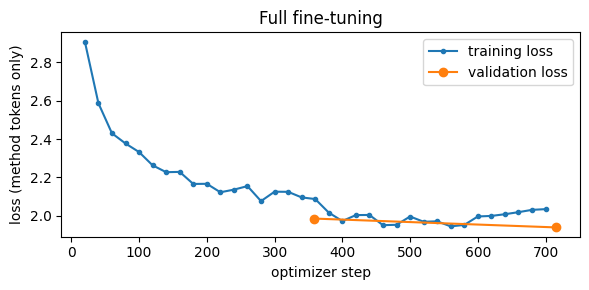

{'trainable': '124,439,808', 'minutes': 6.47, 'peak GB': 11.01} | final validation loss 1.94
Exercise 5 checks passed.


In [ ]:
from accelerate.utils import extract_model_from_parallel


def collate(batch, pad_id=tokenizer.pad_token_id):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), pad_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train(model, args, train_data, eval_data, title, data_collator=collate):
    trainer = Trainer(model=model, args=args, train_dataset=train_data, eval_dataset=eval_data,
                      data_collator=data_collator)
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    extract_model_from_parallel(model, keep_fp32_wrapper=False)
    stats = {"trainable": count_trainable(model), "minutes": (time.perf_counter() - start) / 60,
             "peak GB": torch.cuda.max_memory_allocated() / GB if HAS_GPU else float("nan")}
    log = trainer.state.log_history
    tr = [(h["step"], h["loss"]) for h in log if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in log if "eval_loss" in h]
    plt.figure(figsize=(6, 3))
    if tr:
        plt.plot(*zip(*tr), marker=".", label="training loss")
    plt.plot(*zip(*ev), marker="o", label="validation loss")
    plt.xlabel("optimizer step"); plt.ylabel("loss (method tokens only)"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.show()
    print({k: (f"{v:,}" if k == "trainable" else round(v, 2)) for k, v in stats.items()},
          "| final validation loss", round(ev[-1][1], 3))
    return stats, ev[-1][1]


transformers.set_seed(SEED)
full_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
full_stats, full_val_loss = train(full_model, make_args("full", FULL_LR), train_data, val_data, "Full fine-tuning")
assert full_stats["trainable"] == 124_439_808, "full fine-tuning trains every GPT-2 parameter"
print("Exercise 5 checks passed.")

In [ ]:
!pip install -q --upgrade torchao

In [ ]:
from peft import LoraConfig, get_peft_model
LORA_LR = 5e-4
transformers.set_seed(SEED)
lora_base = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
predicted_lora_params = 8 * (768 + 2304) * 12
lora_config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05, target_modules=['c_attn'], task_type='CAUSAL_LM', fan_in_fan_out=True)
lora_model = get_peft_model(lora_base, lora_config)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
predicted_lora_params = 8 * (768 + 2304) * 12
lora_model.print_trainable_parameters()
assert count_trainable(lora_model) == predicted_lora_params
assert predicted_lora_params == 294_912
print('Exercise 6 configuration checks passed.')

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364
Exercise 6 configuration checks passed.


In [ ]:
lora_stats, lora_val_loss = train(lora_model, make_args("lora", LORA_LR), train_data, val_data, "LoRA (r = 8, c_attn)")
pd.DataFrame({"full fine-tuning": full_stats | {"val loss": full_val_loss},
              "LoRA": lora_stats | {"val loss": lora_val_loss}}).T

In [ ]:
start = time.perf_counter()
full_preds, full_stopped = generate_methods(full_model, tokenizer, eval_rows, add_bos=False)
lora_preds, lora_stopped = generate_methods(lora_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {2 * len(eval_rows)} methods in {time.perf_counter() - start:.0f} s")
evaluate("GPT-2 full FT", full_preds, full_stopped)
table = evaluate("GPT-2 LoRA", lora_preds, lora_stopped)
table

In [ ]:
for i in (0, 1, 2):
    r = eval_rows[i]
    print(f"=================== {r['name']} ===================")
    print("INGREDIENTS:", "; ".join(r["ingredients"]))
    for name, preds in (("REFERENCE", refs), ("FULL FT", full_preds), ("LORA", lora_preds)):
        print(f"\n{name}: {preds[i][:700]}")
    print()

In [ ]:
GENERAL_TEXTS = [
    "The train to Jaipur left the station twenty minutes late. Most passengers had already found their seats, "
    "and a few were reading newspapers while the countryside moved slowly past the windows.",
    "Rainwater that falls on the hills collects in small streams, which join to form rivers. Some of the water "
    "soaks into the ground and is stored in aquifers that supply wells during the dry season.",
    "The committee will meet on Monday to discuss the budget for the next financial year. Members are asked to "
    "read the report in advance and to send any questions to the secretary by Friday.",
    "In the final over, the batsman needed twelve runs to win. He hit the first ball for four, missed the next "
    "two, and then lifted a full toss over long-on for six.",
]

In [ ]:
@torch.no_grad()
def mean_loss(model, texts):
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    for text in texts:
        input_ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"].to(DEVICE)
        if input_ids.size(1) < 2:
            continue
        loss = model(input_ids=input_ids, labels=input_ids).loss
        n_tokens = input_ids.size(1) - 1
        total_loss += float(loss) * n_tokens
        total_tokens += n_tokens
    return total_loss / max(total_tokens, 1)


In [ ]:
forgetting = {name: mean_loss(m, GENERAL_TEXTS) for name, m in
              (("GPT-2 original", base_model), ("GPT-2 full FT", full_model), ("GPT-2 LoRA", lora_model))}
for name, loss in forgetting.items():
    print(f"{name:<16} loss on general English {loss:.3f}  (perplexity {math.exp(loss):.1f})")
with lora_model.disable_adapter():
    assert abs(mean_loss(lora_model, GENERAL_TEXTS) - forgetting["GPT-2 original"]) < 1e-3
print("Exercise 7 checks passed.")

In [ ]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
lora_model.save_pretrained(ADAPTER_DIR)
adapter_mb = sum(f.stat().st_size for f in ADAPTER_DIR.iterdir()) / 1e6
print(f"adapter on disk: {adapter_mb:.2f} MB | GPT-2 in fp32: {124_439_808 * 4 / 1e6:.0f} MB")

probe = tokenizer(format_prompt(eval_rows[0]), return_tensors="pt").to(DEVICE)
with torch.no_grad():
    before = lora_model(**probe).logits
    merged = lora_model.merge_and_unload()
    after = merged(**probe).logits
print(f"largest logit change after merging: {(before - after).abs().max().item():.2e}")
assert (before - after).abs().max().item() < 1e-2, "merging should change the logits only by rounding"
assert sum(p.numel() for p in merged.parameters()) == 124_439_808
assert not any("lora" in n for n, _ in merged.named_parameters())

In [ ]:
RUN_LLAMA = False
LLAMA_CKPT = "meta-llama/Llama-3.2-1B"
LLAMA_N_TRAIN, LLAMA_N_EVAL = 1000, 20


def hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")


if RUN_LLAMA:
    assert HAS_GPU, "the Llama extension needs a GPU"
    import gc
    del base_model, full_model, lora_model, lora_base, merged
    gc.collect(); torch.cuda.empty_cache()
    HF_TOKEN = hf_token()
    assert HF_TOKEN, "no Hugging Face token found: see 'Access' above"
    llama_tok = AutoTokenizer.from_pretrained(LLAMA_CKPT, token=HF_TOKEN)
    if llama_tok.pad_token is None:
        llama_tok.pad_token = llama_tok.eos_token
    print("BOS", repr(llama_tok.bos_token), llama_tok.bos_token_id, "| EOS", repr(llama_tok.eos_token), llama_tok.eos_token_id)
    for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
        print(f"{word:>8} -> {llama_tok.tokenize(' ' + word)}")
    sample = splits["train"][:200]
    n_gpt2 = sum(len(build_example(r, tokenizer, False)["input_ids"]) for r in sample)
    n_llama = sum(len(build_example(r, llama_tok, True)["input_ids"]) for r in sample)
    print(f"tokens for 200 training recipes: GPT-2 {n_gpt2:,} | Llama {n_llama:,} ({n_llama / n_gpt2:.2f}x)")

In [ ]:
if RUN_LLAMA:
    llama_train = make_dataset(splits["train"][:LLAMA_N_TRAIN], llama_tok, add_bos=True)
    e = llama_train[0]
    print("first tokens:", llama_tok.convert_ids_to_tokens(e["input_ids"][:4]),
          "| last:", llama_tok.convert_ids_to_tokens(e["input_ids"][-2:]))
    assert e["input_ids"][0] == llama_tok.bos_token_id and e["input_ids"][1] != llama_tok.bos_token_id
    assert e["input_ids"][-1] == llama_tok.eos_token_id
    llama_rows = eval_rows[:LLAMA_N_EVAL]

    transformers.set_seed(SEED)
    llama = AutoModelForCausalLM.from_pretrained(LLAMA_CKPT, dtype=torch.float16, token=HF_TOKEN, device_map={"": 0})
    print(f"Llama parameters: {sum(p.numel() for p in llama.parameters()):,} | "
          f"GPU memory after loading: {torch.cuda.memory_allocated() / GB:.2f} GB")
    print(llama.model.layers[0].self_attn)

In [ ]:
def llama_lora_config():
    return LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
                      task_type="CAUSAL_LM")


LLAMA_PREDICTED = 16 * (2 * 16 * (2048 + 2048) + 2 * 16 * (2048 + 512))


LoRA parameters: 294912


Epoch,Training Loss,Validation Loss
1,2.513102,2.355188
2,2.498615,2.313887


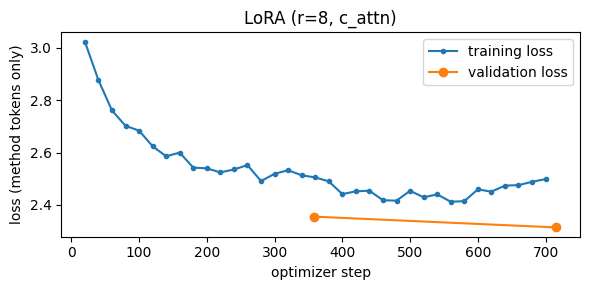

{'trainable': '294,912', 'minutes': 5.68, 'peak GB': 10.64} | final validation loss 2.314
generated 80 methods in 53 s
                        BLEU  ROUGE-1  ROUGE-2  ROUGE-L  ingredients %  words  \
GPT-2 original           3.7     30.8      6.9     17.4           56.3  219.0   
GPT-2 full fine-tuning  10.2     46.2     17.6     29.2           76.2  166.3   
GPT-2 LoRA               9.2     41.7     13.9     26.0           73.0  219.3   

                        stopped %  
GPT-2 original               65.0  
GPT-2 full fine-tuning       95.0  
GPT-2 LoRA                   87.5  
                        BLEU  ROUGE-1  ROUGE-2  ROUGE-L  ingredients %  words  \
GPT-2 original           3.7     30.8      6.9     17.4           56.3  219.0   
GPT-2 full fine-tuning  10.2     46.2     17.6     29.2           76.2  166.3   
GPT-2 LoRA               9.4     41.7     14.3     26.1           74.6  217.1   

                        stopped %  
GPT-2 original               65.0  
GPT-2 full fine

In [ ]:
predicted_lora_params = 8 * (768 + 2304) * 12
assert count_trainable(lora_model) == predicted_lora_params
print("LoRA parameters:", predicted_lora_params)
lora_stats, lora_val_loss = train(lora_model, make_args("lora", LORA_LR), train_data, val_data, "LoRA (r=8, c_attn)")
start = time.perf_counter()
full_preds, full_stopped = generate_methods(full_model, tokenizer, eval_rows, add_bos=False)
lora_preds, lora_stopped = generate_methods(lora_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {2 * len(eval_rows)} methods in {time.perf_counter() - start:.0f} s")
print(evaluate("GPT-2 full fine-tuning", full_preds, full_stopped))
print(evaluate("GPT-2 LoRA", lora_preds, lora_stopped))
forgetting = {name: mean_loss(model, GENERAL_TEXTS) for name, model in (("GPT-2 original", base_model), ("GPT-2 full FT", full_model), ("GPT-2 LoRA", lora_model))}
for name, loss in forgetting.items(): print(f"{name}: loss={loss:.3f}, perplexity={math.exp(loss):.1f}")
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
lora_model.save_pretrained(ADAPTER_DIR)
print("Adapter files:", sorted(p.name for p in ADAPTER_DIR.iterdir()))

In [ ]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True); lora_model.save_pretrained(ADAPTER_DIR); print("Adapter files:", sorted(path.name for path in ADAPTER_DIR.iterdir())); probe = tokenizer(format_prompt(eval_rows[0]), return_tensors="pt").to(DEVICE); before = lora_model(**probe).logits; merged = lora_model.merge_and_unload(); after = merged(**probe).logits; print("Maximum merge logit difference:", float((before - after).abs().max())); assert (before - after).abs().max().item() < 1e-2

Adapter files: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
Maximum merge logit difference: 0.00046539306640625


In [ ]:
if RUN_LLAMA:
    llama_base_preds, llama_base_stopped = generate_methods(llama, llama_tok, llama_rows, add_bos=True)
    llama_lora = get_peft_model(llama, llama_lora_config())
    llama_lora.print_trainable_parameters()
    assert count_trainable(llama_lora) == LLAMA_PREDICTED, "prediction and peft disagree"
    llama_args = TrainingArguments(
        output_dir=str(OUT / "llama_lora"), per_device_train_batch_size=4, gradient_accumulation_steps=2,
        num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10, fp16=True,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        eval_strategy="epoch", logging_steps=10, save_strategy="no", report_to="none",
        remove_unused_columns=False, seed=SEED)
    llama_val = make_dataset(splits["val"][:100], llama_tok, add_bos=True)
    llama_stats, llama_val_loss = train(llama_lora, llama_args, llama_train, llama_val, "Llama-3.2-1B, LoRA r = 16",
                                        data_collator=lambda b: collate(b, pad_id=llama_tok.pad_token_id))
    llama_lora_preds, llama_lora_stopped = generate_methods(llama_lora, llama_tok, llama_rows, add_bos=True)

In [ ]:
if RUN_LLAMA:
    from IPython.display import display
    results.clear()
    k = LLAMA_N_EVAL
    for name, preds, stopped in (("GPT-2 original", base_preds[:k], base_stopped[:k]),
                                 ("GPT-2 full FT", full_preds[:k], full_stopped[:k]),
                                 ("GPT-2 LoRA", lora_preds[:k], lora_stopped[:k]),
                                 ("Llama original", llama_base_preds, llama_base_stopped)):
        evaluate(name, preds, stopped, llama_rows)
    display(evaluate("Llama LoRA", llama_lora_preds, llama_lora_stopped, llama_rows))
    for i in (0, 1):
        print(f"=== {llama_rows[i]['name']} ===\nLLAMA LoRA: {llama_lora_preds[i][:700]}\nGPT-2 LoRA: {lora_preds[i][:700]}\n")